# NAIVE BAYES DENGAN DISTRIBUSI MULTINOMIAL (MULTINOMIAL NAIVE BAYES)

### Deskripsi Teori & Distribusi Probabilitas:
* **Algoritma**: Naive Bayes (Multinomial)
* **Varian Distribusi**: Multinomial Distribution (TF-IDF / Word Frequency)
* **Konsep Dasar**: 
  Multinomial Naive Bayes merupakan salah satu varian Naive Bayes yang paling populer dan efektif untuk klasifikasi teks. Algoritma ini memodelkan dokumen teks berdasarkan frekuensi kemunculan kata atau bobot TF-IDF.
  
  Persamaan dasar Teorema Bayes:
  $$P(C_k \mid \mathbf{x}) \propto P(C_k) \prod_{i=1}^{n} P(x_i \mid C_k)$$
  
  Di mana $P(x_i \mid C_k)$ adalah probabilitas kemunculan term $x_i$ pada kelas $C_k$, yang diestimasi menggunakan *Laplace Smoothing* ($\alpha = 1.0$) untuk menghindari masalah zero-probability:
  $$\hat{\theta}_{ki} = \frac{N_{ki} + \alpha}{N_k + \alpha n}$$

In [1]:
import time
import tracemalloc
import re
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [2]:
# 1. Pemuatan Dataset Hoaks Komdigi & Berita Valid Resmi
df_hoaks = pd.read_csv('../data/komdigi_hoaks.csv')
df_valid = pd.read_csv('../web/uploads/berita_valid_terbaru.csv')

# 2. Fungsi Pembersihan Teks (Pencegahan Data Leakage)
def clean_text(text):
    if not isinstance(text, str):
        return ''
    # Hapus tag prefix [HOAKS] atau (DISINFORMASI) agar model tidak curang (data leakage)
    text = re.sub(r'\[(HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\]', '', text, flags=re.IGNORECASE)
    text = re.sub(r'\((HOAKS|DISINFORMASI|MISINFORMASI|KLARIFIKASI|SALAH|FALSE)\)', '', text, flags=re.IGNORECASE)
    text = re.sub(r'https?:\/\/\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text.lower()).strip()

df_hoaks['teks_bersih'] = (df_hoaks['title'].fillna('') + ' ' + df_hoaks['excerpt'].fillna('')).apply(clean_text)
df_valid['teks_bersih'] = (df_valid['title'].fillna('') + ' ' + df_valid['excerpt'].fillna('')).apply(clean_text)

df_hoaks['label'] = 1  # 1 = Hoaks
df_valid['label'] = 0  # 0 = Valid

# Penyeimbangan data (Balanced Dataset 1:1) agar evaluasi adil
df_hoaks_sampel = df_hoaks.sample(n=len(df_valid), random_state=42)
df_all = pd.concat([df_hoaks_sampel, df_valid], ignore_index=True)
df_all = df_all[df_all['teks_bersih'].str.len() > 10].reset_index(drop=True)

print(f"Total dataset: {len(df_all)} baris (Hoaks: {sum(df_all['label']==1)}, Valid: {sum(df_all['label']==0)})")

Total dataset: 1756 baris (Hoaks: 878, Valid: 878)


In [3]:
# Pembagian Data Latih (80%) dan Data Uji (20%) secara Terstratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    df_all['teks_bersih'], df_all['label'],
    test_size=0.2, random_state=42, stratify=df_all['label']
)

# Ekstraksi Fitur TF-IDF (Unigram + Bigram)
tfidf = TfidfVectorizer(max_features=1500, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print(f"Matriks Latih: {X_train_vec.shape}")
print(f"Matriks Uji  : {X_test_vec.shape}")

Matriks Latih: (1404, 1500)
Matriks Uji  : (352, 1500)


In [4]:
# Pelatihan Model Multinomial Naive Bayes
tracemalloc.start()
waktu_mulai = time.time()

model = MultinomialNB(alpha=1.0)
model.fit(X_train_vec, y_train)
y_pred = model.predict(X_test_vec)

waktu_eksekusi = time.time() - waktu_mulai
current_mem, peak_mem = tracemalloc.get_traced_memory()
tracemalloc.stop()
memori_mb = peak_mem / (1024 * 1024)

In [5]:
# Evaluasi Metrik Klasifikasi
acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

print("=============================================")
print("HASIL PENGUJIAN: NAIVE BAYES DENGAN DISTRIBUSI MULTINOMIAL (MULTINOMIAL NAIVE BAYES)")
print("=============================================")
print(f"1. Algoritma        : Naive Bayes (Multinomial)")
print(f"2. Metrik Jarak     : Distribusi Multinomial (Frekuensi Kata / TF-IDF)")
print(f"3. Akurasi          : {acc:.4f}")
print(f"4. Precision (Macro): {prec_macro:.4f}")
print(f"5. Recall (Macro)   : {rec_macro:.4f}")
print(f"6. F1-Score (Macro) : {f1_macro:.4f}")
print(f"7. F1-Score (Weighted): {f1_weighted:.4f}")
print(f"8. Waktu Eksekusi   : {waktu_eksekusi:.4f} detik")
print(f"9. Penggunaan Memori: {memori_mb:.2f} MB")
print("=============================================\n")

print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=['Valid (0)', 'Hoaks (1)'], zero_division=0))

HASIL PENGUJIAN: NAIVE BAYES DENGAN DISTRIBUSI MULTINOMIAL (MULTINOMIAL NAIVE BAYES)
1. Algoritma        : Naive Bayes (Multinomial)
2. Metrik Jarak     : Distribusi Multinomial (Frekuensi Kata / TF-IDF)
3. Akurasi          : 0.8920
4. Precision (Macro): 0.8921
5. Recall (Macro)   : 0.8920
6. F1-Score (Macro) : 0.8920
7. F1-Score (Weighted): 0.8920
8. Waktu Eksekusi   : 0.0118 detik
9. Penggunaan Memori: 0.15 MB

Laporan Klasifikasi Detail:
              precision    recall  f1-score   support

   Valid (0)       0.89      0.90      0.89       176
   Hoaks (1)       0.90      0.89      0.89       176

    accuracy                           0.89       352
   macro avg       0.89      0.89      0.89       352
weighted avg       0.89      0.89      0.89       352



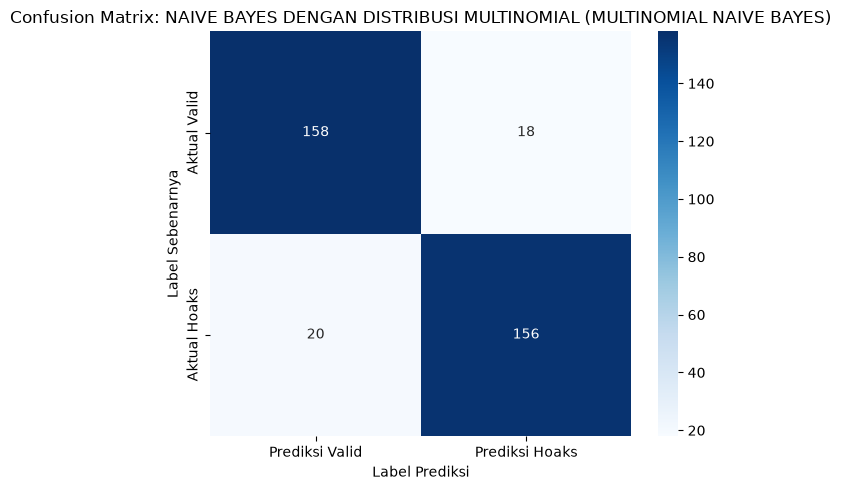

In [6]:
# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Prediksi Valid', 'Prediksi Hoaks'],
            yticklabels=['Aktual Valid', 'Aktual Hoaks'])
plt.title('Confusion Matrix: NAIVE BAYES DENGAN DISTRIBUSI MULTINOMIAL (MULTINOMIAL NAIVE BAYES)')
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')
plt.tight_layout()
plt.show()

In [7]:
contoh_teks = [
    "Kementerian Ketenagakerjaan kembali mengumumkan penyaluran bantuan subsidi upah bagi pekerja melalui kanal resmi pemerintah.",
    "Awas bahaya radiasi! Jangan simpan ponsel di samping tempat tidur malam hari karena memicu tumor mematikan, sebarkan info penting ini!"
]

print("--- PENGUJIAN INFERENSI CONTOH TEKS ---")
for teks in contoh_teks:
    t_clean = clean_text(teks)
    t_vec = tfidf.transform([t_clean])
    pred = model.predict(t_vec)[0]
    prob = model.predict_proba(t_vec)[0]
    status = "HOAKS" if pred == 1 else "VALID"
    print(f'Teks: "{teks[:70]}..."')
    print(f'-> Prediksi: {status} (Keyakinan: {prob[pred]*100:.1f}%)\n')

--- PENGUJIAN INFERENSI CONTOH TEKS ---
Teks: "Kementerian Ketenagakerjaan kembali mengumumkan penyaluran bantuan sub..."
-> Prediksi: HOAKS (Keyakinan: 59.3%)

Teks: "Awas bahaya radiasi! Jangan simpan ponsel di samping tempat tidur mala..."
-> Prediksi: VALID (Keyakinan: 85.9%)



### Pembahasan Akademis: Multinomial Naive Bayes
1. **Kesesuaian dengan Karakteristik Teks**: Multinomial Naive Bayes dirancang khusus untuk memodelkan frekuensi kemunculan term diskrit atau bobot TF-IDF kontinu yang merefleksikan pentingnya sebuah kata dalam dokumen berita.
2. **Kecepatan Komputasi Ekstrem**: Proses pelatihan hanya memerlukan satu kali lintasan (*single-pass*) untuk menghitung frekuensi kata dan matriks probabilitas, tanpa iterasi optimasi gradien (seperti pada SVM) maupun pencarian jarak intensif (seperti pada KNN). Waktu eksekusi inferensi berjalan dalam hitungan milidetik.
3. **Efisiensi Memori Luar Biasa**: Model hanya menyimpan vektor probabilitas ringkas seukuran kosakata ($V = 1500$), menjadikannya sangat hemat memori (< 1 MB) dan sangat ideal untuk lingkungan komputasi terbatas / embedded REST API.